## 1. Imports

In [4]:
from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Project paths


In [75]:
PROJECT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

FULL_CLEAN_DATA_PATH = PROJECT_DIR / "processed_10hz" / "clean_dataset_for_pca.csv"

SPLIT_DIR = PROJECT_DIR / "splits"

TRAIN_SPLIT_PATH = SPLIT_DIR / "train_model_ready_selected_features.csv"
VAL_SPLIT_PATH = SPLIT_DIR / "val_model_ready_selected_features.csv"
TEST_SPLIT_PATH = SPLIT_DIR / "test_model_ready_selected_features.csv"

PCA_OUTPUT_DIR = PROJECT_DIR / "model_ready_with_pca"
PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("PCA input dataset:", FULL_CLEAN_DATA_PATH)
print("Split directory:", SPLIT_DIR)
print("PCA output directory:", PCA_OUTPUT_DIR)

Project directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project
PCA input dataset: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_dataset_for_pca.csv
Split directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits
PCA output directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_with_pca


## 3. cleaned full dataset loading from eda cleaning

In [76]:
if not FULL_CLEAN_DATA_PATH.exists():
    raise FileNotFoundError(f"PCA input dataset not found: {FULL_CLEAN_DATA_PATH}")

df = pd.read_csv(FULL_CLEAN_DATA_PATH, low_memory=False)

print("PCA input dataset loaded.")
print("Shape:", df.shape)
print("Unique flights:", df["log_id"].nunique())

print("\nLabel distribution:")
print(df["dataset_label"].value_counts())

display(df.head())

PCA input dataset loaded.
Shape: (971822, 378)
Unique flights: 168

Label distribution:
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Loading same train/validation/test flight IDs

In [77]:
for path in [TRAIN_SPLIT_PATH, VAL_SPLIT_PATH, TEST_SPLIT_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Split file not found: {path}")

train_split_df = pd.read_csv(TRAIN_SPLIT_PATH, low_memory=False)
val_split_df = pd.read_csv(VAL_SPLIT_PATH, low_memory=False)
test_split_df = pd.read_csv(TEST_SPLIT_PATH, low_memory=False)

for split_name, split_data in {
    "train_split_df": train_split_df,
    "val_split_df": val_split_df,
    "test_split_df": test_split_df
}.items():
    if "log_id" not in split_data.columns:
        raise ValueError(f"log_id missing from {split_name}")

train_ids = set(train_split_df["log_id"].astype(str).unique())
val_ids = set(val_split_df["log_id"].astype(str).unique())
test_ids = set(test_split_df["log_id"].astype(str).unique())

print("Train flights:", len(train_ids))
print("Validation flights:", len(val_ids))
print("Test flights:", len(test_ids))

Train flights: 117
Validation flights: 25
Test flights: 26


## 5. Flight-level leakage check

to check whether the same flight log appears in more than one dataset split.

In [78]:
print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("No flight-level leakage found.")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
No flight-level leakage found.


## 6. Flight-level leakage check

checks whether filtering by the split IDs accidentally removed any rows or flights.

In [79]:
all_split_ids = train_ids | val_ids | test_ids

before_rows = df.shape[0]
before_flights = df["log_id"].nunique()

df = df[df["log_id"].isin(all_split_ids)].copy()

after_rows = df.shape[0]
after_flights = df["log_id"].nunique()

print("Rows before filtering to split IDs:", before_rows)
print("Rows after filtering to split IDs:", after_rows)

print("Flights before:", before_flights)
print("Flights after:", after_flights)

print("\nLabel distribution after filtering:")
print(df["dataset_label"].value_counts())

Rows before filtering to split IDs: 971822
Rows after filtering to split IDs: 971822
Flights before: 168
Flights after: 168

Label distribution after filtering:
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


## 8. train/validation/test datasets from full clean data

In [80]:
train_df = df[df["log_id"].isin(train_ids)].copy()
val_df = df[df["log_id"].isin(val_ids)].copy()
test_df = df[df["log_id"].isin(test_ids)].copy()

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain labels:")
print(train_df["dataset_label"].value_counts())

print("\nValidation labels:")
print(val_df["dataset_label"].value_counts())

print("\nTest labels:")
print(test_df["dataset_label"].value_counts())

Train shape: (694549, 378)
Validation shape: (138749, 378)
Test shape: (138524, 378)

Train labels:
dataset_label
normal      497250
abnormal    197299
Name: count, dtype: int64

Validation labels:
dataset_label
normal      92724
abnormal    46025
Name: count, dtype: int64

Test labels:
dataset_label
normal      100406
abnormal     38118
Name: count, dtype: int64


## 9. target and leakage columns

In [81]:
target_col = "target_energy_next_60s_wh"

non_feature_cols = [
    "log_id",
    "dataset_label",
    "time_td"
]

leakage_cols = [
    "target_energy_next_60s_wh",
    "future_cumulative_energy_wh",
    "future_remaining_60s",
    "target_remaining_drop_60s"
]

cols_to_exclude = non_feature_cols + leakage_cols

existing_excluded_cols = [
    col for col in cols_to_exclude
    if col in df.columns
]

print("Excluded columns:")
for col in existing_excluded_cols:
    print("-", col)

Excluded columns:
- log_id
- dataset_label
- time_td
- target_energy_next_60s_wh
- future_cumulative_energy_wh


## 10. numeric candidate features selection

removes target/leakage/non-feature columns

In [82]:
numeric_cols = [
    col for col in df.columns
    if pd.api.types.is_numeric_dtype(df[col])
]

feature_cols = [
    col for col in numeric_cols
    if col not in leakage_or_non_feature_cols
]

print("Initial numeric candidate feature count:", len(feature_cols))
print(feature_cols)

Initial numeric candidate feature count: 367
['actuator_outputs__noutputs', 'actuator_outputs__output[0]', 'actuator_outputs__output[1]', 'actuator_outputs__output[2]', 'actuator_outputs__output[3]', 'actuator_outputs__output[4]', 'actuator_outputs__output[5]', 'actuator_outputs__output[6]', 'actuator_outputs__output[7]', 'actuator_outputs__output[8]', 'actuator_outputs__output[9]', 'actuator_outputs__output[10]', 'actuator_outputs__output[11]', 'actuator_outputs__output[12]', 'actuator_outputs__output[13]', 'actuator_outputs__output[14]', 'actuator_outputs__output[15]', 'actuator_outputs_1__noutputs', 'actuator_outputs_1__output[0]', 'actuator_outputs_1__output[1]', 'actuator_outputs_1__output[2]', 'actuator_outputs_1__output[3]', 'actuator_outputs_1__output[4]', 'actuator_outputs_1__output[5]', 'actuator_outputs_1__output[6]', 'actuator_outputs_1__output[7]', 'actuator_outputs_1__output[8]', 'actuator_outputs_1__output[9]', 'actuator_outputs_1__output[10]', 'actuator_outputs_1__outpu

## 11. Removing timestamp related colomns

because they mainly represented sensor logging time rather than useful flight or battery behaviour.

In [83]:
timestamp_like_cols = [
    "actuator_outputs_1__time_td",
    "sensor_combined__accelerometer_timestamp_relative",
    "sensor_combined__magnetometer_timestamp_relative",
    "sensor_combined__baro_timestamp_relative",
    "vehicle_attitude__time_td",
    "vehicle_gps_position__time_utc_usec",
    "vehicle_gps_position__timestamp_time_relative",
    "vehicle_gps_position__time_td",
    "vehicle_local_position__ref_timestamp",
    "vehicle_local_position__surface_bottom_timestamp",
    "vehicle_local_position__time_td",
    "vehicle_air_data__time_td",
    "vehicle_angular_velocity__timestamp_sample",
    "vehicle_status__nav_state_timestamp",
    "vehicle_acceleration__timestamp_sample",
    "vehicle_air_data__timestamp_sample",
    "vehicle_attitude__timestamp_sample",
    "vehicle_local_position__timestamp_sample",
    "vehicle_status__failsafe_timestamp",
    "vehicle_status__armed_time",
    "vehicle_status__takeoff_time",
    "airspeed__time_td",
    "actuator_motors__timestamp_sample",
    "actuator_motors__time_td",
    "vehicle_gps_position__timestamp_sample"
]

timestamp_like_cols = [
    col for col in timestamp_like_cols
    if col in feature_cols
]

print("Timestamp-like columns to remove:", len(timestamp_like_cols))
print(timestamp_like_cols)

feature_cols = [
    col for col in feature_cols
    if col not in timestamp_like_cols
]

print("Feature count after timestamp-like removal:", len(feature_cols))

Timestamp-like columns to remove: 25
['actuator_outputs_1__time_td', 'sensor_combined__accelerometer_timestamp_relative', 'sensor_combined__magnetometer_timestamp_relative', 'sensor_combined__baro_timestamp_relative', 'vehicle_attitude__time_td', 'vehicle_gps_position__time_utc_usec', 'vehicle_gps_position__timestamp_time_relative', 'vehicle_gps_position__time_td', 'vehicle_local_position__ref_timestamp', 'vehicle_local_position__surface_bottom_timestamp', 'vehicle_local_position__time_td', 'vehicle_air_data__time_td', 'vehicle_angular_velocity__timestamp_sample', 'vehicle_status__nav_state_timestamp', 'vehicle_acceleration__timestamp_sample', 'vehicle_air_data__timestamp_sample', 'vehicle_attitude__timestamp_sample', 'vehicle_local_position__timestamp_sample', 'vehicle_status__failsafe_timestamp', 'vehicle_status__armed_time', 'vehicle_status__takeoff_time', 'airspeed__time_td', 'actuator_motors__timestamp_sample', 'actuator_motors__time_td', 'vehicle_gps_position__timestamp_sample']


## 12. duplicate feature removal

energy_increment_wh = power_w × time interval / 3600

In [84]:
if "power_w" in feature_cols and "energy_increment_wh" in feature_cols:
    feature_cols.remove("energy_increment_wh")
    print("Removed energy_increment_wh because power_w already captures the same energy-use signal at 10 Hz.")

print("Feature count after duplicate-style removal:", len(feature_cols))
print(feature_cols)

Removed energy_increment_wh because power_w already captures the same energy-use signal at 10 Hz.
Feature count after duplicate-style removal: 341
['actuator_outputs__noutputs', 'actuator_outputs__output[0]', 'actuator_outputs__output[1]', 'actuator_outputs__output[2]', 'actuator_outputs__output[3]', 'actuator_outputs__output[4]', 'actuator_outputs__output[5]', 'actuator_outputs__output[6]', 'actuator_outputs__output[7]', 'actuator_outputs__output[8]', 'actuator_outputs__output[9]', 'actuator_outputs__output[10]', 'actuator_outputs__output[11]', 'actuator_outputs__output[12]', 'actuator_outputs__output[13]', 'actuator_outputs__output[14]', 'actuator_outputs__output[15]', 'actuator_outputs_1__noutputs', 'actuator_outputs_1__output[0]', 'actuator_outputs_1__output[1]', 'actuator_outputs_1__output[2]', 'actuator_outputs_1__output[3]', 'actuator_outputs_1__output[4]', 'actuator_outputs_1__output[5]', 'actuator_outputs_1__output[6]', 'actuator_outputs_1__output[7]', 'actuator_outputs_1__out

## 13. Create X and y

In [106]:
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()


X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape) # series 1d, 1 colomn
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (694549, 17)
X_val: (138749, 17)
X_test: (138524, 17)

y_train: (694549,)
y_val: (138749,)
y_test: (138524,)


## 14. Removing rows with missing target if any

In [86]:
print("Missing target values:")
print("Train:", y_train.isna().sum())
print("Validation:", y_val.isna().sum())
print("Test:", y_test.isna().sum())

# Usually this should be zero because target cleaning was already done
train_valid_target = ~y_train.isna()
val_valid_target = ~y_val.isna()
test_valid_target = ~y_test.isna()

X_train = X_train.loc[train_valid_target].copy()
y_train = y_train.loc[train_valid_target].copy()
train_df = train_df.loc[train_valid_target].copy()

X_val = X_val.loc[val_valid_target].copy()
y_val = y_val.loc[val_valid_target].copy()
val_df = val_df.loc[val_valid_target].copy()

X_test = X_test.loc[test_valid_target].copy()
y_test = y_test.loc[test_valid_target].copy()
test_df = test_df.loc[test_valid_target].copy()

print("After target check:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

Missing target values:
Train: 0
Validation: 0
Test: 0
After target check:
X_train: (694549, 341)
X_val: (138749, 341)
X_test: (138524, 341)


## 15. Missing-value report before filtering

In [87]:
missing_report_before = pd.DataFrame({
    "feature": feature_cols,
    "train_missing_%": X_train.isna().mean().values * 100,
    "val_missing_%": X_val.isna().mean().values * 100,
    "test_missing_%": X_test.isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(missing_report_before)

missing_report_before.to_csv(
    PCA_OUTPUT_DIR / "missing_report_before_pca_filtering.csv",
    index=False
)

,feature,train_missing_%,val_missing_%,test_missing_%
340,vehicle_status__pre_flight_checks_pass,100.0,100.0,100.0
113,vehicle_local_position__v_xy_valid,100.0,100.0,100.0
144,vehicle_status__time_td,100.0,100.0,100.0
306,vehicle_gps_position__altitude_msl_m,100.0,100.0,100.0
305,vehicle_gps_position__longitude_deg,100.0,100.0,100.0
...,...,...,...,...
39,battery_status__remaining,0.0,0.0,0.0
38,battery_status__discharged_mah,0.0,0.0,0.0
34,battery_status__voltage_v,0.0,0.0,0.0
35,battery_status__voltage_filtered_v,0.0,0.0,0.0


## 16. Remove 100% missing, >80% missing, and constant columns using train only

In [88]:
MISSING_THRESHOLD = 80

train_missing_percent = X_train.isna().mean() * 100
train_unique_counts = X_train.nunique(dropna=True)

cols_100_missing = train_missing_percent[train_missing_percent == 100].index.tolist()
cols_high_missing = train_missing_percent[train_missing_percent > MISSING_THRESHOLD].index.tolist()
cols_constant = train_unique_counts[train_unique_counts <= 1].index.tolist()

cols_to_drop = sorted(list(set(cols_100_missing + cols_high_missing + cols_constant)))

print("100% missing columns:", len(cols_100_missing))
print(cols_100_missing)

print("\nMore than 80% missing columns:", len(cols_high_missing))
print(cols_high_missing)

print("\nConstant columns:", len(cols_constant))
print(cols_constant)

print("\nTotal columns to drop:", len(cols_to_drop))

100% missing columns: 225
['actuator_outputs_1__noutputs', 'actuator_outputs_1__output[0]', 'actuator_outputs_1__output[1]', 'actuator_outputs_1__output[2]', 'actuator_outputs_1__output[3]', 'actuator_outputs_1__output[4]', 'actuator_outputs_1__output[5]', 'actuator_outputs_1__output[6]', 'actuator_outputs_1__output[7]', 'actuator_outputs_1__output[8]', 'actuator_outputs_1__output[9]', 'actuator_outputs_1__output[10]', 'actuator_outputs_1__output[11]', 'actuator_outputs_1__output[12]', 'actuator_outputs_1__output[13]', 'actuator_outputs_1__output[14]', 'actuator_outputs_1__output[15]', 'sensor_combined__magnetometer_ga[0]', 'sensor_combined__magnetometer_ga[1]', 'sensor_combined__magnetometer_ga[2]', 'sensor_combined__baro_alt_meter', 'sensor_combined__baro_temp_celcius', 'vehicle_attitude__rollspeed', 'vehicle_attitude__pitchspeed', 'vehicle_attitude__yawspeed', 'vehicle_attitude__q[0]', 'vehicle_attitude__q[1]', 'vehicle_attitude__q[2]', 'vehicle_attitude__q[3]', 'vehicle_gps_positio

## 17. feature filtering

In [89]:
feature_cols_filtered = [col for col in feature_cols if col not in cols_to_drop]

X_train = X_train[feature_cols_filtered].copy()
X_val = X_val[feature_cols_filtered].copy()
X_test = X_test[feature_cols_filtered].copy()

feature_cols = feature_cols_filtered

print("Final candidate feature count before imputation/scaling/PCA:", len(feature_cols))
print(feature_cols)

Final candidate feature count before imputation/scaling/PCA: 17
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'cumulative_energy_wh', 'battery_status__system_source', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']


## 18. Missing-value report after filtering

In [90]:
missing_report_after = pd.DataFrame({
    "feature": feature_cols,
    "train_missing_%": X_train.isna().mean().values * 100,
    "val_missing_%": X_val.isna().mean().values * 100,
    "test_missing_%": X_test.isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(missing_report_after)

missing_report_after.to_csv(
    PCA_OUTPUT_DIR / "missing_report_after_pca_filtering.csv",
    index=False
)

,feature,train_missing_%,val_missing_%,test_missing_%
16,battery_status__voltage_cell_v[3],76.076850,75.316579,70.920563
15,battery_status__voltage_cell_v[2],76.076850,75.316579,70.920563
14,battery_status__voltage_cell_v[1],76.076850,75.316579,70.920563
13,battery_status__voltage_cell_v[0],76.076850,75.316579,70.920563
12,battery_status__system_source,17.373144,8.877902,13.349311
9,time_s,0.000000,0.000000,0.000000
11,cumulative_energy_wh,0.000000,0.000000,0.000000
10,power_w,0.000000,0.000000,0.000000
0,battery_status__voltage_v,0.000000,0.000000,0.000000
1,battery_status__voltage_filtered_v,0.000000,0.000000,0.000000


## 19. Median imputation fitted on train only

In [91]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

print("Missing values after median imputation:")
print("Train:", np.isnan(X_train_imputed).sum())
print("Validation:", np.isnan(X_val_imputed).sum())
print("Test:", np.isnan(X_test_imputed).sum())

Missing values after median imputation:
Train: 0
Validation: 0
Test: 0


## 20. Standardisation

Mean ≈ 0
Standard deviation ≈ 1

In [92]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (694549, 17)
Scaled validation shape: (138749, 17)
Scaled test shape: (138524, 17)


## 21. Scaling

In [93]:
scaled_train_check = pd.DataFrame(X_train_scaled, columns=feature_cols)

scale_summary = pd.DataFrame({
    "feature": feature_cols,
    "scaled_train_mean": scaled_train_check.mean().values,
    "scaled_train_std": scaled_train_check.std().values
})

display(scale_summary)

scale_summary.to_csv(
    PCA_OUTPUT_DIR / "scaling_check_before_pca.csv",
    index=False
)

,feature,scaled_train_mean,scaled_train_std
0,battery_status__voltage_v,-2.514192e-16,1.000001
1,battery_status__voltage_filtered_v,4.818869e-16,1.000001
2,battery_status__current_a,1.990402e-16,1.000001
3,battery_status__current_filtered_a,9.428222e-17,1.000001
4,battery_status__discharged_mah,1.466612e-16,1.000001
5,battery_status__remaining,1.335665e-16,1.000001
6,battery_status__scale,1.539943e-15,1.000001
7,battery_status__cell_count,0.000000e+00,1.000001
8,battery_status__warning,-1.571370e-17,1.000001
9,time_s,8.380641e-17,1.000001


## 22. fit PCA on training data

In [94]:
pca_full = PCA(random_state=42)

X_train_pca_full = pca_full.fit_transform(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_variance_df = pd.DataFrame({
    "component_number": range(1, len(explained_variance) + 1),
    "component": [f"PC{i+1}" for i in range(len(explained_variance))],
    "explained_variance_ratio": explained_variance,
    "cumulative_variance": cumulative_variance
})

display(pca_variance_df)

pca_variance_df.to_csv(
    PCA_OUTPUT_DIR / "pca_explained_variance_full.csv",
    index=False
)

,component_number,component,explained_variance_ratio,cumulative_variance
0,1,PC1,3.609020e-01,0.360902
1,2,PC2,2.096482e-01,0.570550
2,3,PC3,1.311789e-01,0.701729
3,4,PC4,1.014051e-01,0.803134
4,5,PC5,5.823785e-02,0.861372
5,6,PC6,5.472137e-02,0.916093
6,7,PC7,4.373912e-02,0.959833
7,8,PC8,2.490076e-02,0.984733
8,9,PC9,7.930194e-03,0.992663
9,10,PC10,3.361603e-03,0.996025


## 23. Scree plot

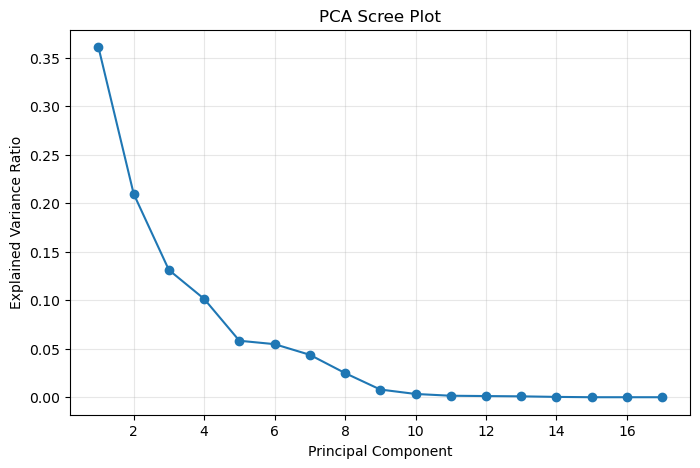

In [95]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid(True, alpha=0.3)
plt.show()

## 24. Cumulative explained variance plot

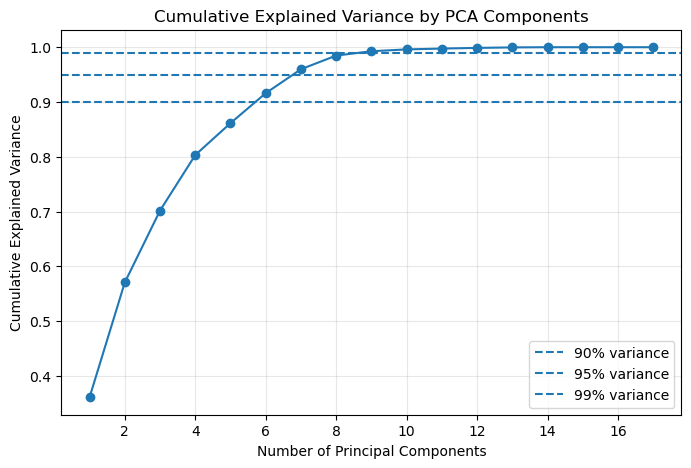

In [96]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.axhline(y=0.99, linestyle="--", label="99% variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance by PCA Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 25. PCA component count selection

In [97]:
variance_threshold = 0.95

n_components = np.argmax(cumulative_variance >= variance_threshold) + 1

print(f"Selected variance threshold: {variance_threshold * 100:.0f}%")
print("Original candidate feature count:", len(feature_cols))
print("Selected PCA component count:", n_components)
print("Variance retained:", cumulative_variance[n_components - 1])

print("\nComponent counts for common thresholds:")
for threshold in [0.90, 0.95, 0.99]:
    n = np.argmax(cumulative_variance >= threshold) + 1
    print(f"{threshold*100:.0f}% variance: {n} components")

Selected variance threshold: 95%
Original candidate feature count: 17
Selected PCA component count: 7
Variance retained: 0.9598325299360358

Component counts for common thresholds:
90% variance: 6 components
95% variance: 7 components
99% variance: 9 components


## 26. Fitting final PCA using selected components

In [98]:
pca = PCA(n_components=n_components, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

pca_feature_cols = [f"PC{i+1}" for i in range(n_components)]

print("X_train_pca:", X_train_pca.shape)
print("X_val_pca:", X_val_pca.shape)
print("X_test_pca:", X_test_pca.shape)

print("PCA feature columns:")
print(pca_feature_cols)

X_train_pca: (694549, 7)
X_val_pca: (138749, 7)
X_test_pca: (138524, 7)
PCA feature columns:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7']


## 27. PCA loadings

Which original features contribute most to each PCA component

In [99]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=pca_feature_cols
)

display(loadings)

loadings.to_csv(PCA_OUTPUT_DIR / "pca_loadings.csv")

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
battery_status__voltage_v,0.311392,-0.053144,0.364672,-0.170012,0.073890,-0.030324,-0.167520
battery_status__voltage_filtered_v,0.313638,-0.052365,0.364329,-0.167495,0.073087,-0.030539,-0.166415
battery_status__current_a,0.224484,0.250750,-0.139195,0.471580,0.014651,-0.051134,-0.018864
battery_status__current_filtered_a,0.226342,0.252707,-0.140017,0.467113,0.014480,-0.048893,-0.018311
battery_status__discharged_mah,0.264369,0.318079,-0.051273,0.001022,-0.085558,0.036300,0.267775
battery_status__remaining,-0.029468,-0.305223,0.395394,0.312848,0.059916,-0.110537,0.390805
battery_status__scale,0.067204,0.339989,-0.323448,-0.344576,-0.077082,0.088434,-0.344693
battery_status__cell_count,0.326420,0.011035,0.318739,-0.183561,0.058530,-0.012683,-0.240687
battery_status__warning,0.008111,0.068878,-0.087535,-0.023779,0.911293,0.380012,0.099966
time_s,0.102400,0.220989,-0.056726,-0.399858,-0.091176,0.014722,0.676101


## 28. Top contributing features per component

In [100]:
top_loading_rows = []

for pc in pca_feature_cols:
    top_features = (
        loadings[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nTop contributing features for {pc}:")
    display(top_features)

    for feature, abs_value in top_features.items():
        top_loading_rows.append({
            "principal_component": pc,
            "feature": feature,
            "absolute_loading": abs_value,
            "signed_loading": loadings.loc[feature, pc]
        })

top_loadings_df = pd.DataFrame(top_loading_rows)

top_loadings_df.to_csv(
    PCA_OUTPUT_DIR / "pca_top_feature_contributors.csv",
    index=False
)


Top contributing features for PC1:


battery_status__cell_count            0.326420
power_w                               0.321636
battery_status__voltage_filtered_v    0.313638
battery_status__voltage_v             0.311392
cumulative_energy_wh                  0.285675
Name: PC1, dtype: float64


Top contributing features for PC2:


battery_status__scale                0.339989
battery_status__discharged_mah       0.318079
battery_status__voltage_cell_v[3]    0.314322
battery_status__voltage_cell_v[0]    0.314322
battery_status__voltage_cell_v[2]    0.314322
Name: PC2, dtype: float64


Top contributing features for PC3:


...

battery_status__warning           0.911293
battery_status__system_source     0.353762
time_s                            0.091176
battery_status__discharged_mah    0.085558
battery_status__scale             0.077082
Name: PC5, dtype: float64


Top contributing features for PC6:


battery_status__system_source    0.907380
battery_status__warning          0.380012
battery_status__remaining        0.110537
battery_status__scale            0.088434
power_w                          0.058198
Name: PC6, dtype: float64


Top contributing features for PC7:


time_s                            0.676101
battery_status__remaining         0.390805
battery_status__scale             0.344693
battery_status__discharged_mah    0.267775
cumulative_energy_wh              0.243175
Name: PC7, dtype: float64

## 28. Creating PCA model-ready datasets

In [101]:
X_train_pca_df = pd.DataFrame(X_train_pca, columns=pca_feature_cols)
X_val_pca_df = pd.DataFrame(X_val_pca, columns=pca_feature_cols)
X_test_pca_df = pd.DataFrame(X_test_pca, columns=pca_feature_cols)

train_pca = pd.concat([
    train_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_train_pca_df.reset_index(drop=True),
    y_train.reset_index(drop=True).rename(target_col)
], axis=1)

val_pca = pd.concat([
    val_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_val_pca_df.reset_index(drop=True),
    y_val.reset_index(drop=True).rename(target_col)
], axis=1)

test_pca = pd.concat([
    test_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_test_pca_df.reset_index(drop=True),
    y_test.reset_index(drop=True).rename(target_col)
], axis=1)

print("PCA train:", train_pca.shape)
print("PCA validation:", val_pca.shape)
print("PCA test:", test_pca.shape)

display(train_pca.head())

PCA train: (694549, 10)
PCA validation: (138749, 10)
PCA test: (138524, 10)


,log_id,dataset_label,PC1,PC2,PC3,PC4,PC5,PC6,PC7,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.688519,-1.117910,0.466354,0.103070,-0.026943,0.228327,-0.336776,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.688490,-1.117850,0.466338,0.102960,-0.026968,0.228331,-0.336590,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.688462,-1.117789,0.466323,0.102850,-0.026993,0.228335,-0.336403,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.688434,-1.117728,0.466307,0.102740,-0.027018,0.228339,-0.336217,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.652988,-0.967748,0.310618,-0.007742,-0.054850,0.266449,-0.491433,0.001109


## 29. Final quality check

In [102]:
def check_dataset(name, data):
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", data.shape)
    print("Missing values:", data.isna().sum().sum())
    print("Unique flights:", data["log_id"].nunique())
    print("Target missing:", data[target_col].isna().sum())
    print("Label distribution:")
    print(data["dataset_label"].value_counts())

check_dataset("Train PCA", train_pca)
check_dataset("Validation PCA", val_pca)
check_dataset("Test PCA", test_pca)


Train PCA
----------------------------------------
Shape: (694549, 10)
Missing values: 0
Unique flights: 117
Target missing: 0
Label distribution:
dataset_label
normal      497250
abnormal    197299
Name: count, dtype: int64

Validation PCA
----------------------------------------
Shape: (138749, 10)
Missing values: 0
Unique flights: 25
Target missing: 0
Label distribution:
dataset_label
normal      92724
abnormal    46025
Name: count, dtype: int64

Test PCA
----------------------------------------
Shape: (138524, 10)
Missing values: 0
Unique flights: 26
Target missing: 0
Label distribution:
dataset_label
normal      100406
abnormal     38118
Name: count, dtype: int64


## 30. PCA datasets saving

In [103]:
train_pca.to_csv(PCA_OUTPUT_DIR / "train_pca_95.csv", index=False)
val_pca.to_csv(PCA_OUTPUT_DIR / "val_pca_95.csv", index=False)
test_pca.to_csv(PCA_OUTPUT_DIR / "test_pca_95.csv", index=False)

print("Saved PCA datasets to:")
print(PCA_OUTPUT_DIR)

Saved PCA datasets to:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_with_pca


## 31. Saving  preprocessing objects and feature lists
will be useful for reproducability

In [104]:
joblib.dump(imputer, PCA_OUTPUT_DIR / "median_imputer_pca.joblib")
joblib.dump(scaler, PCA_OUTPUT_DIR / "standard_scaler_pca.joblib")
joblib.dump(pca, PCA_OUTPUT_DIR / "pca_95_model.joblib")

with open(PCA_OUTPUT_DIR / "candidate_feature_columns_before_pca.json", "w") as f:
    json.dump(feature_cols, f, indent=4)

with open(PCA_OUTPUT_DIR / "pca_feature_columns.json", "w") as f:
    json.dump(pca_feature_cols, f, indent=4)

print("Saved imputer, scaler, PCA model, and feature lists.")

Saved imputer, scaler, PCA model, and feature lists.
